# Module 6 · Lab 6.2 — Observability with LangSmith & Langfuse
## Four questions a production team could not answer, and what it takes to answer each one

---

## Business Scenario: ShopSmart — Flying Blind in Production

ShopSmart's AI support agent has been live for two months. It works. Nobody can tell you *how*
well, because the engineering team cannot answer four basic questions:

| # | The question | Why they cannot answer it |
|---|---|---|
| **1** | *"Why did Mrs. Sharma get a bad answer?"* | A platinum customer complained about a wrong order-status reply yesterday. There are **no traces** — no record of which path the agent took, which tools it called, or what the model actually saw. |
| **2** | *"What is our P95 latency?"* | Customers say it is "slow". There are **no metrics**. P50, P95, P99 — all unknown. |
| **3** | *"Why did the bill triple?"* | The OpenAI invoice went up 3× last month. Bad prompts? More tickets? A retry loop? **No cost tracking**, so nobody knows. |
| **4** | *"Did the new prompt help?"* | Last week's prompt change shipped blind. **No before/after comparison.** It may have made things worse. |

Every one of those is answerable with the same thing: a **trace** — a record of what the agent
did, attached to who it did it for and what it cost.

**What you will do:** wire two observability platforms — **LangSmith** and **Langfuse** — to the
*same* ShopSmart agent, run tickets through both, and compare what each shows you. Section 7
comes back and answers all four questions with the traces you produced.

### How this lab is organised

**One question per section.** Each opens with a question ShopSmart cannot answer, walks into the
wall that makes it unanswerable, and introduces exactly the mechanism that removes the wall — so
every tool arrives because something needed it, not because it was next in a catalogue.

| § | The question | What you end up building |
|---|---|---|
| **1–2** | *(setup)* | keys, and the agent you are going to watch |
| **3** | **Q1** — why did this customer get a bad answer? | `@observe`, then both platforms wired to the agent — and **proved** connected |
| **4** | **Q1, still** — which trace is hers? | user, session, ticket and release attached to every run |
| **5** | **Q2 + Q3** — how slow, and how much? | typed spans, so cost exists at all; grouping, so it means something |
| **6** | **Q4** — did the new prompt help? | two labelled releases, compared, with a score on each run |
| **7** | *(recap)* | the scoreboard: every question, and what it cost to answer |
| **8** | *(decision)* | LangSmith or Langfuse — including the case for neither |
| **A** | *(reference)* | tracing with no LangChain: `@traceable`, `wrap_openai`, `wrap_anthropic`, the Langfuse drop-in |

Work 3 → 7 in order; they build on each other. **Appendix A is a lookup table** — skip it until
you need to trace something that is not a LangChain runnable.

If a platform key is missing, that section prints what it would have done and the rest still
runs.

> **What this lab leaves out.** A `BaseCallbackHandler` you own, emitting structured audit
> records that survive a change of vendor, is the durable half of observability and genuinely
> the more valuable one. This lab focuses on the two platforms.

### Learning objectives
1. Trace any Python function with the **`@observe`** decorator — the simplest entry point there is
2. Configure LangSmith and Langfuse against a real LangGraph agent
3. **Prove** each backend is connected — both fail silently, in different ways
4. Attach user, session, release and tags so an incident is searchable months later
5. Score a run programmatically, so eval results and production traces live in one place
6. Answer the four questions above from a dashboard rather than a guess

### Prerequisites
- `OPENAI_API_KEY` · Labs 5.1, 6.1
- Optional: `LANGSMITH_API_KEY` (§4, §6) · `LANGFUSE_PUBLIC_KEY` + `LANGFUSE_SECRET_KEY` (§3, §5, §6)
- Optional: `ANTHROPIC_API_KEY` — only for §6c, which traces a raw Anthropic call. Every other
  cell runs without it.


### The failure mode this lab is built to prevent

> **`get_client()` never raises without credentials.** Verified against langfuse 3.14.5: with no
> keys set it prints an authentication error to *stderr* — which Colab routinely swallows — and
> returns a healthy-looking client whose `_tracing_enabled` is `True`. Every span you create is
> accepted, and none of it is ever recorded.
>
> An observability tool that silently observes nothing is worse than no observability tool,
> because you will stop looking. Both platform sections therefore begin by **proving** the
> connection rather than assuming it.


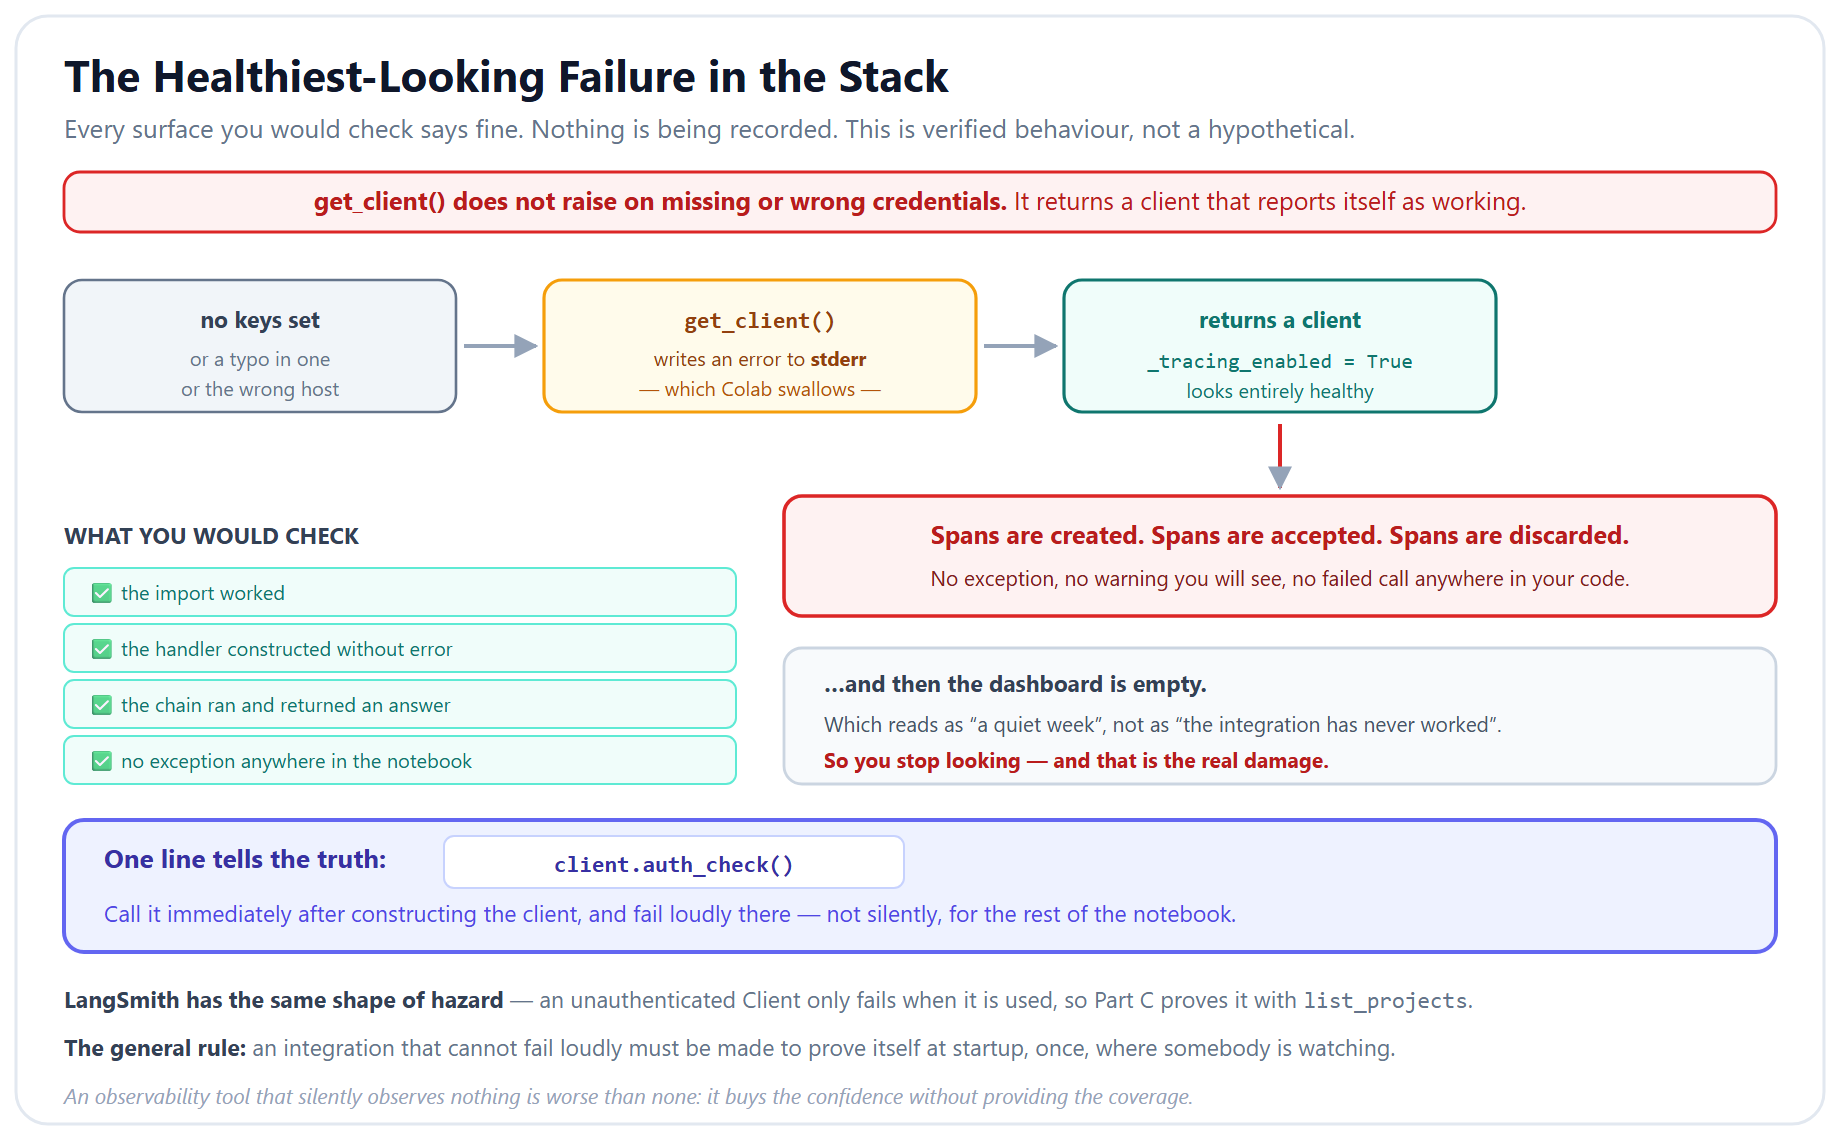

**Figure — The healthiest-looking failure in the stack.** `get_client()` accepts missing credentials, logs to stderr where Colab swallows it, and returns a client reporting `_tracing_enabled=True`. Spans are created, accepted and discarded. Every surface you would check says fine, and the dashboard is simply empty — which reads as "quiet week". `auth_check()` is the only call that tells the truth.


---

## 1. Setup


In [ ]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-openai langgraph langsmith langfuse openai anthropic pandas python-dotenv

In [1]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"\U0001F511 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")


# This is an observability lab, so the platform keys are PREREQUISITES, not options.
# Every cell below assumes all five are present. The assert stops you here, with a clear
# message, rather than letting a cell six sections down fail in a confusing way.
REQUIRED_KEYS = ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "LANGSMITH_API_KEY",
                 "LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY"]
load_keys(REQUIRED_KEYS)

missing_keys = [name for name in REQUIRED_KEYS if not os.environ.get(name)]
assert not missing_keys, f"missing required keys: {missing_keys}"

os.environ.setdefault("LANGFUSE_HOST", "https://cloud.langfuse.com")

# --- Imports ---
import json
import re
import time
import uuid
from typing import Literal, TypedDict

import pandas as pd

from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langgraph.graph import END, StateGraph
from pydantic import BaseModel, Field

# Two models, matching Lab 5.3: a reasoning model routes, a cheaper one answers.
reasoning_model = ChatOpenAI(model="gpt-5-mini")            # no temperature parameter
chat_model = ChatOpenAI(model="gpt-4.1-mini", temperature=0.3)

# One session id for the whole notebook. Both platforms use it to group the runs below into
# a single conversation, which is what separates 'one unhappy customer' from 'an outage'.
support_session_id = f"session-{uuid.uuid4().hex[:12]}"
print(f"\nsession id: {support_session_id}")
print("Ready.")

🔑 Key source: .env / environment
   OPENAI_API_KEY         ✅
   ANTHROPIC_API_KEY      ✅
   LANGSMITH_API_KEY      ✅
   LANGFUSE_PUBLIC_KEY    ✅
   LANGFUSE_SECRET_KEY    ✅

session id: session-0afd7704fd3b
Ready.



---

## 2. The system we are going to watch

Observability is only teachable against a system that *has something to observe*. A single
prompt-model-parser chain produces one span; there is nothing in it to search for, group by, or
compare across releases, so every worked example ends up abstract.

So this lab instruments **the Spine A routing agent** — the same classify-then-route shape Lab 5.3
evaluates, over the same PROJECT 2 data. One ticket produces a trace with real shape:

```
graph run                       <- one trace, one session, one user
 ├─ classify_query   -> gpt-5-mini      <- routing decision + its cost
 └─ handle_returns   -> gpt-4.1-mini    <- the answer + its cost
```

That shape is what makes the rest of the lab concrete. "Which customer hit this?" has an answer.
"What did it cost?" has *two* answers, per node, and they are not the same. "Was it routed
correctly?" is a question you can only ask because there is a routing step to record.

> **One rule before you send anything.** Guardrails run *before* the tracer, not after. If your
> trace records the raw input and Lab 6.1's Layer 3 redacts afterwards, you have faithfully
> archived every piece of PII you were trying to protect — in a third-party system, with a
> different retention policy, that your compliance review has probably never seen. Note that the
> metadata below carries an opaque `customer_id`, never the name or email the ticket also holds.


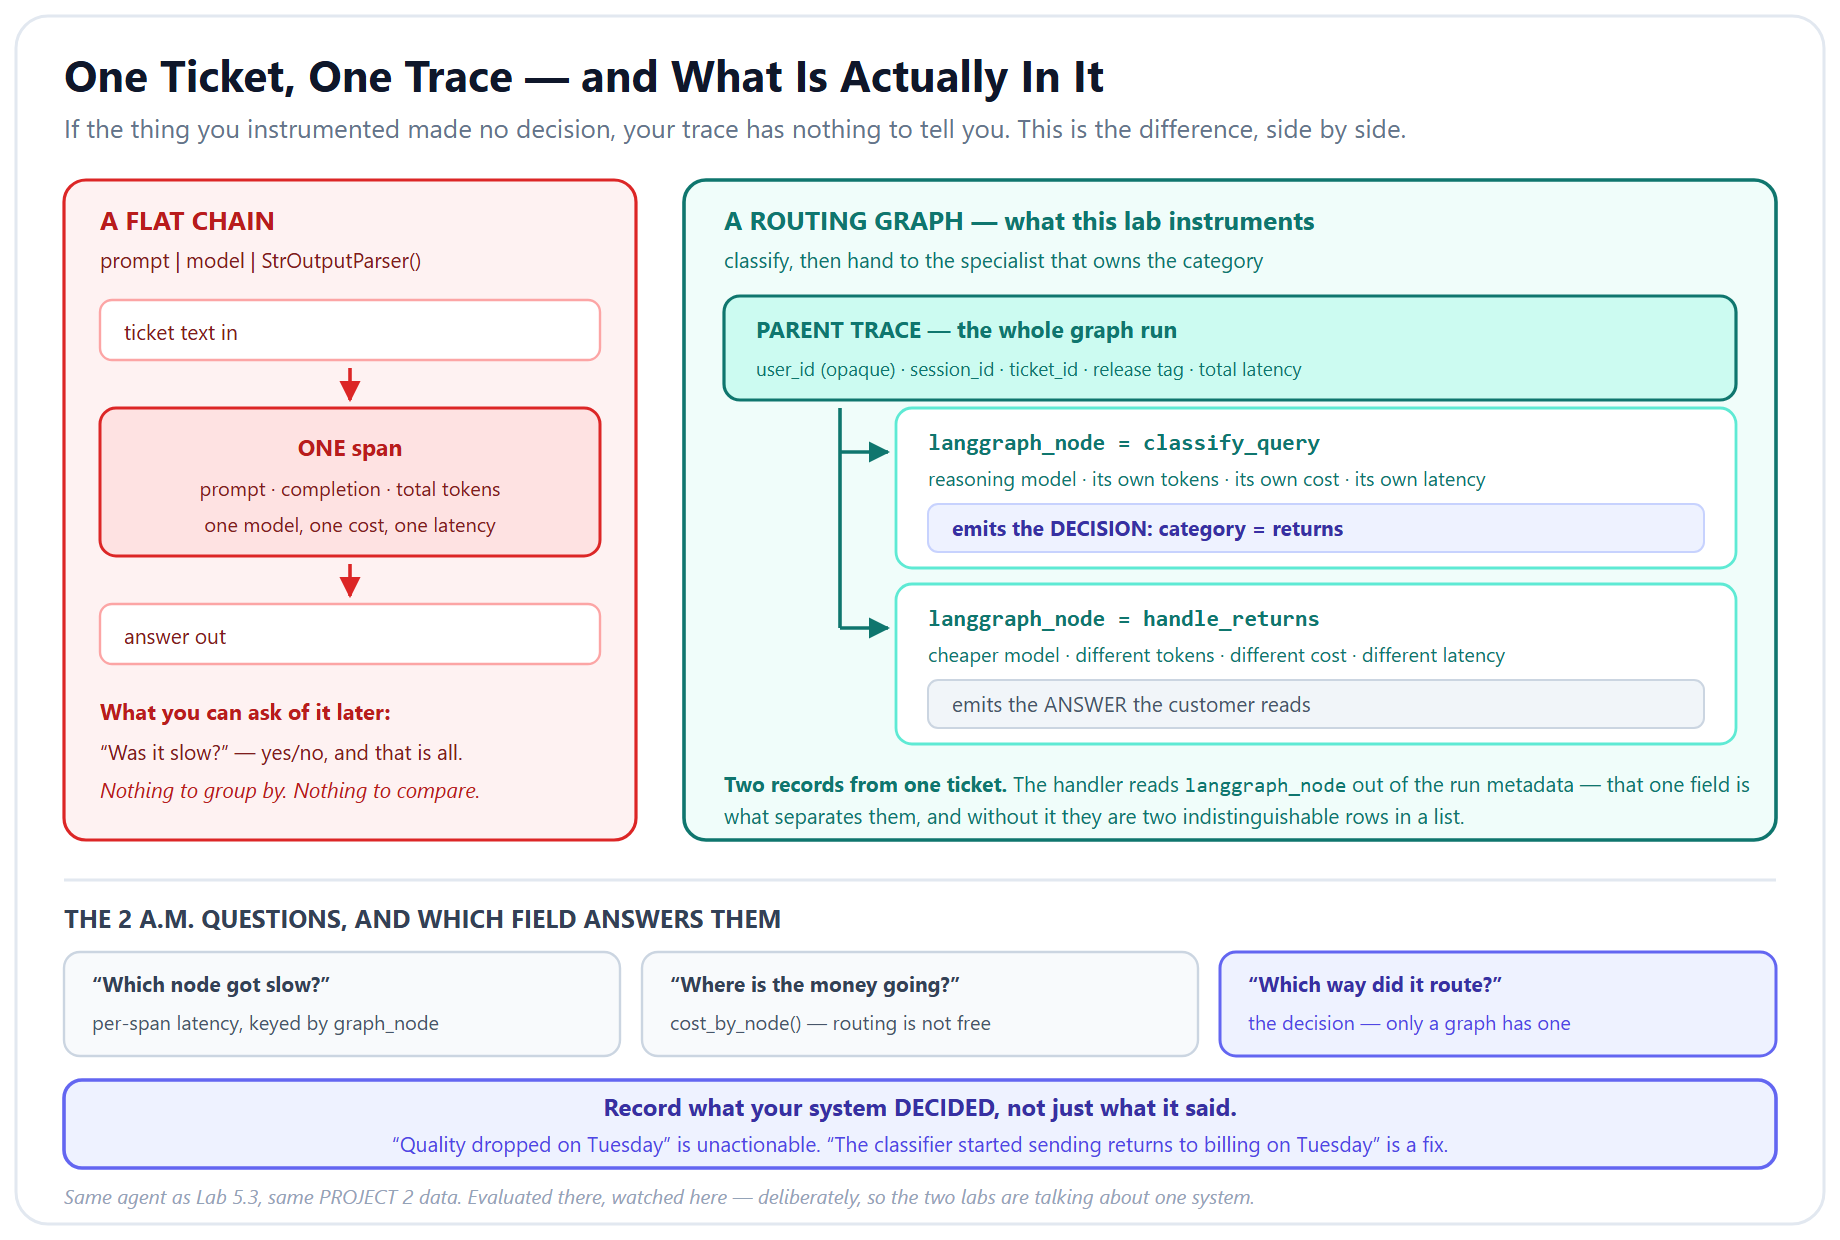

**Figure — What is actually in a trace, and what is not.** A flat chain produces one span: a prompt, a completion, one cost, nothing to group by. The routing graph produces a parent trace with a child span per node, each carrying its own model, tokens, cost and latency — and the classifier's span carries the thing that matters most, the **decision**. That is the field that turns "quality dropped on Tuesday" into "the classifier started sending returns to billing on Tuesday", and you cannot record it if the thing you instrumented never decided anything.

In [2]:
# --- Spine A data: PROJECT 2's own files, loaded the way Lab 3.1 loads them ---
# These are the SAME five files Lab 3.1 (PROJECT 2) reads, byte for byte. Nothing is retyped
# and nothing is trimmed, so the join keys survive: a ticket carries a customer_id, a customer
# owns orders, an order references products. Every later lab in this spine depends on that.

def resolve_data_file(file_name):
    """Find one pre-provided Spine A data file across the likely locations.

    Colab users upload the "Lab_6.2 Files" folder next to the notebook; local users may run
    from the module directory or one level above it. Try each in turn.

    Args:
        file_name: a file inside the data folder, e.g. "orders.json".

    Returns:
        The first path that exists.

    Raises:
        FileNotFoundError: if none of the candidate locations contain it.
    """
    candidate_folders = (
        "Lab_6.2 Files/",
        "",
        "../Lab_6.2 Files/",
        "../",
    )
    for base_folder in candidate_folders:
        candidate_path = base_folder + file_name
        if os.path.exists(candidate_path):
            return candidate_path
    raise FileNotFoundError(
        f"Could not find '{file_name}'. On Colab, upload the 'Lab_6.2 Files' folder "
        f"next to this notebook."
    )


def load_json_data_file(file_name):
    """Load one pre-provided JSON data file and return its parsed contents."""
    with open(resolve_data_file(file_name), encoding="utf-8") as data_file:
        return json.load(data_file)


customers_raw = load_json_data_file("customers.json")
orders_raw = load_json_data_file("orders.json")
products_raw = load_json_data_file("products.json")
TICKETS = load_json_data_file("tickets.json")

with open(resolve_data_file("policies.md"), encoding="utf-8") as policies_file:
    POLICIES = policies_file.read()

# Index by primary key for O(1) lookup — exactly the three dictionaries Lab 3.1 builds.
CUSTOMERS_DB = {customer["customer_id"]: customer for customer in customers_raw}
ORDERS_DB = {order["order_id"]: order for order in orders_raw}
PRODUCTS_DB = {product["product_id"]: product for product in products_raw}

# Reverse index: which orders belong to which customer. This join is the reason a support
# agent can answer "what else have I ordered?".
CUSTOMER_ORDERS = {}
for order in orders_raw:
    CUSTOMER_ORDERS.setdefault(order["customer_id"], []).append(order)

print(f"Spine A data loaded from PROJECT 2's own files:")
print(f"  customers : {len(CUSTOMERS_DB):>4}   tiers {sorted({c['tier'] for c in customers_raw})}")
print(f"  orders    : {len(ORDERS_DB):>4}   statuses {sorted({o['status'] for o in orders_raw})}")
print(f"  products  : {len(PRODUCTS_DB):>4}   categories {sorted({p['category'] for p in products_raw})}")
print(f"  tickets   : {len(TICKETS):>4}   categories {sorted({t['category'] for t in TICKETS})}")
print(f"  policies  : {len(POLICIES):>4} characters")
print()
print(f"  join check: {len(CUSTOMER_ORDERS)} of {len(CUSTOMERS_DB)} customers have orders; "
      f"every order's customer_id resolves = "
      f"{all(order['customer_id'] in CUSTOMERS_DB for order in orders_raw)}")


Spine A data loaded from PROJECT 2's own files:
  customers :   10   tiers ['bronze', 'platinum', 'silver']
  orders    :  100   statuses ['cancelled', 'delivered', 'in_transit', 'processing']
  products  :   20   categories ['Books', 'Clothing', 'Electronics', 'Home & Garden', 'Sports']
  tickets   :  100   categories ['billing', 'escalation', 'order_status', 'product_inquiry', 'returns', 'technical']
  policies  : 2974 characters

  join check: 10 of 10 customers have orders; every order's customer_id resolves = True


In [3]:
# --- Split the real policy document into retrievable sections ---
# Just-in-time retrieval needs a corpus with parts. Rather than invent one, we split PROJECT 2's
# actual policies.md on its own top-level headings. The section names below are read OUT of the
# document, never hard-coded, so if the policy file changes this keeps working.

def split_policy_document(policy_markdown):
    """Split a markdown policy document into {section_name: section_text} on its "## " headings.

    Args:
        policy_markdown: the full contents of policies.md.

    Returns:
        An ordered dict-like mapping of lower-cased section key to the section's full text,
        heading included.
    """
    sections = {}
    current_key = None
    current_lines = []
    for line in policy_markdown.splitlines():
        if line.startswith("## "):
            if current_key is not None:
                sections[current_key] = "\n".join(current_lines).strip()
            heading = line[3:].strip()
            current_key = heading.lower().replace(" & ", " ").replace(" ", "_")
            current_lines = [line]
        elif current_key is not None:
            current_lines.append(line)
    if current_key is not None:
        sections[current_key] = "\n".join(current_lines).strip()
    return sections


POLICY_SECTIONS = split_policy_document(POLICIES)
ALL_POLICY_TEXT = "\n\n".join(POLICY_SECTIONS.values())

print(f"policies.md split into {len(POLICY_SECTIONS)} sections:")
for section_key, section_text in POLICY_SECTIONS.items():
    print(f"  {section_key:<22} {len(section_text):>5} chars")
print(f"\n  all sections combined: {len(ALL_POLICY_TEXT)} chars")


policies.md split into 7 sections:
  return_refund_policy     711 chars
  shipping_policy          277 chars
  billing_payment_policy   374 chars
  order_modification_cancellation   384 chars
  customer_service_escalation_criteria   396 chars
  technical_support        408 chars
  special_circumstances    372 chars

  all sections combined: 2934 chars


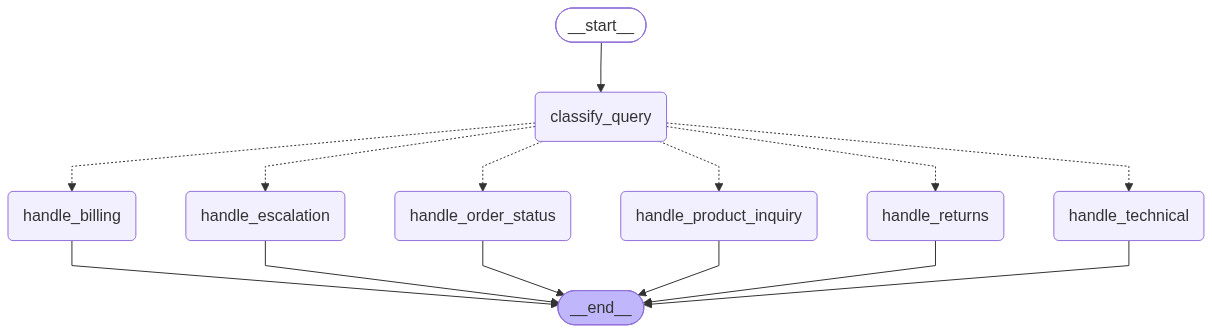

In [4]:
# --- The agent we are going to instrument: the Spine A routing agent ---
# Six categories, taken from the labels tickets.json carries. A classifier picks one, then one
# specialist handler answers with that category's policy section in context.

class AgentState(TypedDict):
    """State for the routing agent under observation."""
    customer_query: str
    category: str
    response: str


TICKET_CATEGORIES = sorted({ticket["category"] for ticket in TICKETS})


class RouteDecision(BaseModel):
    """Structured routing decision, matching PROJECT 2's TicketClassification categories."""
    category: Literal["billing", "escalation", "order_status",
                      "product_inquiry", "returns", "technical"] = Field(
        description="The primary category of the support ticket")


CLASSIFICATION_PROMPT = """Classify this ShopSmart support ticket into exactly one category.

- order_status: where an order is, tracking, delivery estimates
- returns: return or exchange requests, damaged, defective or wrong items
- billing: charges, invoices, refunds, payment amounts
- product_inquiry: product questions, availability, specifications
- technical: account access, password resets, website or app problems
- escalation: the customer asks for a manager, threatens legal or social-media action, or
  expresses extreme dissatisfaction

Ticket: {customer_query}"""

HANDLER_POLICY_SECTIONS = {
    "order_status": "shipping_policy",
    "returns": "return_refund_policy",
    "billing": "billing_payment_policy",
    "product_inquiry": "return_refund_policy",
    "technical": "technical_support",
    "escalation": "customer_service_escalation_criteria",
}

specialist_prompt = ChatPromptTemplate.from_template(
    """You are ShopSmart's {specialism} specialist.

Relevant policy:
{policy}

Reference data:
{reference_data}

Customer message: {query}

Answer the customer directly in 3-5 sentences. Quote the specific order ID, product name,
status, amount or timeframe from the reference data above. All amounts are in US dollars.""")

specialist_chain = specialist_prompt | chat_model | StrOutputParser()


def classify_query(state: AgentState) -> dict:
    """Classify the customer query into one of the six ticket categories."""
    prompt = CLASSIFICATION_PROMPT.format(customer_query=state["customer_query"])
    decision = reasoning_model.with_structured_output(RouteDecision).invoke(prompt)
    return {"category": decision.category}


def build_reference_data(customer_query):
    """Return the order and product records this query refers to, as JSON."""
    matched = {}
    order_match = re.search(r"ORD-\d{5}", customer_query)
    if order_match and order_match.group() in ORDERS_DB:
        matched["order"] = ORDERS_DB[order_match.group()]
    named_products = [product for product in products_raw
                      if product["name"].lower() in customer_query.lower()]
    if named_products:
        matched["products"] = named_products
    return json.dumps(matched, indent=2) if matched else "No specific order or product referenced."


def make_handler(category_name):
    """Return a graph node that answers a query in one category."""
    def handle(state: AgentState) -> dict:
        """Answer the customer with this category's policy and reference data in context."""
        response_text = specialist_chain.invoke({
            "specialism": category_name.replace("_", " "),
            "policy": POLICY_SECTIONS[HANDLER_POLICY_SECTIONS[category_name]],
            "reference_data": build_reference_data(state["customer_query"]),
            "query": state["customer_query"],
        })
        return {"response": response_text}
    handle.__name__ = f"handle_{category_name}"
    return handle


def route_by_category(state: AgentState) -> str:
    """Map the classified category onto the handler node that serves it."""
    return f"handle_{state['category']}"


graph = StateGraph(AgentState)
graph.add_node("classify_query", classify_query)
for category_name in TICKET_CATEGORIES:
    graph.add_node(f"handle_{category_name}", make_handler(category_name))
graph.set_entry_point("classify_query")
graph.add_conditional_edges("classify_query", route_by_category,
                            [f"handle_{name}" for name in TICKET_CATEGORIES])
for category_name in TICKET_CATEGORIES:
    graph.add_edge(f"handle_{category_name}", END)
support_agent = graph.compile()

support_agent

In [5]:

def handle_ticket(ticket_text, config=None):
    """Run one support ticket through the routing agent.

    Args:
        ticket_text: the customer's message.
        config: a LangChain RunnableConfig — this is where callbacks, tags and metadata go.
            Everything this lab does about observability happens through this argument.

    Returns:
        The finished state: the query, the category it routed to, and the response.
    """
    return support_agent.invoke({"customer_query": ticket_text, "category": "", "response": ""},
                                config=config or {})


# A real ticket from the dataset, not a made-up one.
example_ticket = TICKETS[0]
example_result = handle_ticket(example_ticket["text"])
print(f"ticket   : {example_ticket['ticket_id']}  (shipped label: {example_ticket['category']})")
print(f"query    : {example_ticket['text']}")
print(f"routed to: {example_result['category']}")
print(f"response : {example_result['response'][:180]}...")

ticket   : TKT-00001  (shipped label: order_status)
query    : Hi, I'm Sarah Johnson. My email is sarah.j@email.com. What's the tracking number for order ORD-00050?
routed to: order_status
response : Hi Sarah, thank you for reaching out! Your order ORD-00050, which includes 2 Winter Jackets and 2 Yoga Mats totaling $356.68, has been delivered. The tracking number for your order...



---

## 3. Question 1 — "Why Did This Customer Get a Bad Answer?"

Start with the question that got ShopSmart into this lab.

A platinum customer complained about a wrong order-status reply. You have her ticket id. Run it
again and look at what you are actually left with.


In [6]:
# --- What you have TODAY, with no tracing at all ---
complaint_ticket = TICKETS[0]
untraced_result = handle_ticket(complaint_ticket["text"])

print("ticket :", complaint_ticket["ticket_id"])
print("reply  :", untraced_result["response"][:140], "...")

ticket : TKT-00001
reply  : Hi Sarah, thank you for reaching out. Your order ORD-00050, which includes 2 Winter Jackets and 2 Yoga Mats totaling $356.68, has been deliv ...


**And that is everything you have.** A reply, and no account of how it was produced:

| The question | What you can answer today |
|---|---|
| Which category did the classifier pick, and how confidently? | unknown |
| Which policy section did the handler read? | unknown |
| Which model answered, and what did that call cost? | unknown |
| How long did each step take? | unknown |
| Was yesterday's run any different from this one? | unknown |

You cannot debug a reply. You can only debug a **record** of how it was produced.


### The smallest thing that fixes this

A **trace** is that record. The cheapest way to make one is a decorator on a function:

```python
from langfuse import observe

@observe()
def any_function_at_all(...):
    ...
```

Two lines, no framework, and every call now records its name, arguments, return value, duration
and any exception. Start here because it is the whole idea with none of the machinery.


In [7]:
# --- The simplest possible trace: one decorator on one plain function ---
from langfuse import get_client, observe

langfuse_client = get_client()

# get_client() NEVER raises on missing or bad credentials. It returns a healthy-looking
# client whose _tracing_enabled is True, accepts every span, and stores none of them.
# auth_check() is the only call that tells the truth — so assert on it.
assert langfuse_client.auth_check(), "Langfuse rejected these credentials"


@observe()
def summarise_ticket_text(ticket_text):
    """Return a one-line summary of a ticket. Deliberately boring, and not an LLM call.

    The point is that @observe does not care what is inside. It captures the arguments,
    the return value, the duration and any exception, for ANY Python function.
    """
    first_sentence = ticket_text.split(".")[0].strip()
    return f"{first_sentence[:60]} ({len(ticket_text)} chars)"


summary = summarise_ticket_text(TICKETS[0]["text"])
langfuse_client.flush()      # notebooks exit before the background flush; force it
print(f"function returned: {summary}")

function returned: Hi, I'm Sarah Johnson (101 chars)


A trace named `summarise_ticket_text` is now in Langfuse, carrying the **input** (the
`ticket_text` argument), the **output** (the string returned) and the **duration** — none of
which you wrote code to record.

`flush()` is not optional here. Langfuse batches telemetry in the background, so a notebook cell
or a short script can finish and exit before the batch is sent — the trace never arrives and the
dashboard looks empty, which is indistinguishable from a configuration problem. Long-running
servers flush on their own; everything else has to be told.


### But you did not write the inside of the agent

`@observe` traces functions **you** wrote. The ShopSmart agent is a LangGraph graph calling
LangChain models — you cannot decorate its internals, so both platforms give you a hook instead.

| Platform | The hook | Shape |
|---|---|---|
| **LangSmith** | four environment variables | zero code changes; traces everything in the process |
| **Langfuse** | a callback handler | one object, passed per call |

They differ in a way worth noticing now: LangSmith is **on for everything** once configured,
which is convenient and is also a decision — turning it on in a process that handles real
customer data sends that data to a vendor. Langfuse traces only what you hand it.


In [9]:
# --- LangSmith: configure, then PROVE it is connected ---
import langsmith

os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "shopsmart-support-lab-6.2"

# ⚠️ THE LINE EVERY TUTORIAL LEAVES OUT. Both lookups are @functools.lru_cache'd inside the
# LangSmith SDK, and section 2 already ran the agent — caching "tracing = off" and
# "project = default" for the life of this kernel. Without these two cache_clear() calls the
# assignments above are dead code: the notebook runs perfectly and every trace goes nowhere.
langsmith.utils.get_env_var.cache_clear()
langsmith.utils.get_tracer_project.cache_clear()

langsmith_client = langsmith.Client()

# No try/except here on purpose. A bad key SHOULD stop the notebook at this line, loudly,
# rather than print an apology and silently drop every trace below it.
list(langsmith_client.list_projects(limit=1))

# A valid key proves only that we CAN reach LangSmith. These two prove the tracer will fire,
# and will write to the project we asked for.
tracing_is_live = langsmith.utils.tracing_is_enabled()
resolved_project = langsmith.utils.get_tracer_project()
print(f"tracing enabled : {tracing_is_live}")
print(f"target project  : {resolved_project!r}")

assert tracing_is_live is True, "tracing off — the env-var cache was not cleared"
assert resolved_project == os.environ["LANGSMITH_PROJECT"], (
    f"traces would land in {resolved_project!r}, not the project we configured")

tracing enabled : True
target project  : 'shopsmart-support-lab-6.2'


In [10]:
# --- The LangChain bridge: one import, one handler ---
# The client and auth_check already happened in section 3, so this cell only adds the
# piece that connects Langfuse to LangChain.
from langfuse.langchain import CallbackHandler

print("✅ Langfuse client is authenticated (proved in section 3).")
print("   Adding the LangChain callback handler now.")

✅ Langfuse client is authenticated (proved in section 3).
   Adding the LangChain callback handler now.


In [11]:
# --- The handler, with the v3 signature ---
# Note what is NOT here: no secret_key, no host. Passing either raises TypeError in
# v3 — they are read from the environment. This is the most common migration break.
langfuse_handler = CallbackHandler()

result = handle_ticket(
    TICKETS[5]["text"],        # TKT-00006, a damaged-item returns ticket
    config={"callbacks": [langfuse_handler]},
)
print(f"routed to {result['category']}: {result['response'][:140]}...")
print()
print("Unlike LangSmith, nothing here happened by environment variable: Langfuse traced this")
print("run because the handler was passed in explicitly, and would trace nothing without it.")

routed to returns: Hello David, I’m sorry to hear that your item from order ORD-00032 arrived damaged. According to our policy, since your order was delivered ...

Unlike LangSmith, nothing here happened by environment variable: Langfuse traced this
run because the handler was passed in explicitly, and would trace nothing without it.


### Why both of those cells spent their time *proving* the connection

Because **both platforms fail silently, in different ways**, and a tracer that records nothing
looks exactly like a quiet week.

> **Langfuse:** `get_client()` never raises on missing or bad credentials. It logs to *stderr* —
> which Colab routinely swallows — and returns a healthy-looking client whose `_tracing_enabled`
> is `True`. Every span is accepted and none is stored. `auth_check()` is the only call that
> tells the truth.
>
> **LangSmith:** a valid key proves you *can* reach the service, not that the tracer will fire.
> Its environment lookups are memoised on the first runnable that executes, so setting
> `LANGSMITH_TRACING` after your first `.invoke()` is ignored for the rest of the kernel —
> silently. That is why the cell above clears the caches and then asserts
> `tracing_is_enabled()` rather than trusting a ✅ from an auth check.

An observability tool you cannot trust is worse than none, because you stop looking.



---

## 4. Still Question 1 — A Trace You Cannot Find Is a Trace You Do Not Have

You now produce traces. Mrs. Sharma calls. **Which trace is hers?**

Yesterday's run is one of several thousand. Without something to search on, you have swapped "no
record" for "a record you cannot locate", which is not much of an improvement.

Four fields make a run findable, and each answers a different question later:

| Field | Lets you ask |
|---|---|
| `user_id` | "show me everything for this customer" — use an **opaque id**, never a name |
| `session_id` | "was this one bad conversation, or an outage?" |
| `ticket_id` | "show me this exact case" |
| `release` | "did this start when we shipped 2.3.1?" — §6 depends entirely on it |

The PII note matters here. Lab 6.1 spent four layers stripping names and emails; attaching
`"user_id": "Sarah Johnson"` to a third-party trace puts them straight back, in a system with a
different retention policy that your compliance review has probably never seen.


In [12]:
# --- Tags and metadata are what make a trace searchable later ---
# Note there is no `callbacks` entry below. LangSmith needs none: the environment variables set
# in the previous cell trace every runnable in the process. Langfuse, in section 5, is the
# opposite — it does nothing until you pass its handler explicitly.
traced_ticket = TICKETS[6]        # TKT-00007, an order_status ticket about ORD-00070
result = handle_ticket(
    traced_ticket["text"],
    config={
        "run_name": "shopsmart-ticket",
        "tags": ["module-6", "lab-6.2", "shopsmart",
                 f"category:{traced_ticket['category']}"],
        "metadata": {
            # An OPAQUE customer id — the ticket carries a name and an email, and neither
            # belongs in a third-party tracing backend. Lab 6.1 removes them; this is where
            # that discipline pays off.
            "user_id": f"customer_{traced_ticket['customer_id']}",
            "session_id": support_session_id,
            "ticket_id": traced_ticket["ticket_id"],
            "release": "shopsmart-support@2.3.1",
        },
    },
)
print(f"routed to {result['category']}: {result['response'][:140]}...")

# LangSmith batches spans onto a background thread. flush() blocks until they are sent, so
# the run is guaranteed to be in the UI by the time this cell finishes rather than "soon".
langsmith_client.flush()
print(f"flushed to project {os.environ['LANGSMITH_PROJECT']!r} — "
      "open https://smith.langchain.com and select that project (NOT 'default').")
print()
print("Search LangSmith for metadata.release to compare two versions of the prompt.")
print("That comparison is the reason to attach a release tag on every single run.")

routed to order_status: Hi Sarah, your order ORD-00070, which includes 2 Coffee Makers and 2 LED Desk Lamps totaling $579.92, has been delivered. The estimated deli...
flushed to project 'shopsmart-support-lab-6.2' — open https://smith.langchain.com and select that project (NOT 'default').

Search LangSmith for metadata.release to compare two versions of the prompt.
That comparison is the reason to attach a release tag on every single run.


In [13]:
# --- Attaching user, session and tags, the v3 way ---
from langfuse import propagate_attributes

# propagate_attributes() applies these to everything created inside the context
# manager, nested spans included. client.update_current_trace() also still exists and
# sets them on the current trace only — two live APIs, not a forced migration.
with propagate_attributes(
    user_id="customer_a41f9c",
    session_id=support_session_id,      # the same id section 4 attached to its LangSmith run
    tags=["module-6", "lab-6.2"],
):
    # TKT-00012 — the same customer as TKT-00007, which is the point of a session id.
    handle_ticket(TICKETS[11]["text"], config={"callbacks": [langfuse_handler]})

langfuse_client.flush()      # notebooks exit before the background flush; force it
print("✅ Trace sent with user_id, session_id and tags attached.")
print(f"   session {support_session_id} now groups this run with the earlier ticket.")

✅ Trace sent with user_id, session_id and tags attached.
   session session-0afd7704fd3b now groups this run with the earlier ticket.


### ✅ Question 1, answered

Search either dashboard for the session id printed above and you get the run: the ticket text as
the classifier saw it, the category it chose, the policy section retrieved, the model that
answered, and the reply that went out. That is the reconstruction ShopSmart could not do.

**The part worth carrying away:** identity is a **write-time** decision. You cannot add
`user_id` to a run that already happened. Every trace produced before you started attaching it
is permanently anonymous — which is why this cell is boring and important at the same time.



---

## 5. Questions 2 and 3 — "How Slow?" and "How Much?"

These two look similar and are not. **One is free and one is not.**

**Latency is free.** Every span already records its own duration, so P50/P95/P99 is a dashboard
query. The useful move is reading it **per step** rather than per run: this agent's time is
almost entirely one classifier call, and knowing that turns "make the agent faster" into "use a
cheaper model for classification."

**Cost is not free.** A span only carries model, tokens and price if it is labelled as a model
call. That is what `as_type="generation"` does — and it is why the cell below types its spans
instead of leaving them all as generic steps.


In [14]:
# --- Naming, typing, and nesting: three decorated functions, one trace tree ---

@observe(as_type="retriever")
def find_policy_section(category_name):
    """Look up the policy text for a ticket category. Labelled as a retriever step."""
    return POLICY_SECTIONS.get(HANDLER_POLICY_SECTIONS.get(category_name, ""), "")

@observe(name="classify-ticket", as_type="generation")
def classify_ticket_text(ticket_text):
    """Classify a ticket with the reasoning model. Labelled a generation, so Langfuse
    knows to expect model, token and cost fields on this span."""
    decision = reasoning_model.with_structured_output(RouteDecision).invoke(
        CLASSIFICATION_PROMPT.format(customer_query=ticket_text))
    return decision.category

@observe(name="handle-one-ticket")
def handle_one_ticket(ticket_text):
    """Top-level step. The two calls below nest underneath it automatically."""
    category_name = classify_ticket_text(ticket_text)
    policy_text = find_policy_section(category_name)
    return {"category": category_name, "policy_chars": len(policy_text)}

outcome = handle_one_ticket(TICKETS[3]["text"])
langfuse_client.flush()

print(f"result: {outcome}")

result: {'category': 'order_status', 'policy_chars': 277}


In Langfuse that is **one trace with a tree inside it**:

```
handle-one-ticket
  ├─ classify-ticket      (generation — carries model, tokens, cost)
  └─ find_policy_section  (retriever)
```

You nested those spans by calling one function from another. That is the whole API — there is no
parent/child argument to pass.


### ✅ Questions 2 and 3, answered — with one caveat each

**Latency (Q2).** You have per-step timings. Aggregate them in either dashboard.

**Cost (Q3).** You have model and token counts on the generation spans. But a single "tokens
used" total still would not have told ShopSmart why the bill tripled. **Group it:**

| Group by | Catches |
|---|---|
| **user** | one customer in a retry loop |
| **session** | one runaway conversation |
| **release** | a prompt that quietly got 3× longer |

All three of those groupings are only possible because §4 attached the identity. The question
"why did the bill triple?" is really "which of these three changed?", and you cannot ask it of
traces that carry no identity.



---

## 6. Question 4 — "Did the New Prompt Help?"

The last question is different in kind. The first three are answered by *looking at* traces. This
one needs **two populations you can compare**, which means you had to have labelled them *before*
the change shipped.

That is the entire job of the `release` tag from §4. Below, the same tickets run under two
labelled prompt variants, so "is the new prompt better?" becomes a comparison rather than an
opinion.


In [15]:
# --- Two releases, the same tickets, both labelled ---
PROMPT_VARIANTS = {
    "shopsmart-support@2.3.0": "Answer the customer in 3-5 sentences.",
    "shopsmart-support@2.4.0": ("Answer the customer in 3-5 sentences. Always state the order ID "
                                "and the current status explicitly in the first sentence."),
}

comparison_tickets = TICKETS[:3]
release_results = []

for release_label, instruction_suffix in PROMPT_VARIANTS.items():
    for ticket in comparison_tickets:
        started_at = time.time()
        run_config = {
            "run_name": "release-comparison",
            "tags": ["module-6", "lab-6.2", f"release:{release_label}"],
            "metadata": {
                "user_id": f"customer_{ticket['customer_id']}",
                "session_id": support_session_id,
                "ticket_id": ticket["ticket_id"],
                "release": release_label,       # <-- the field the whole comparison rests on
            },
            "callbacks": [langfuse_handler],
        }
        result = handle_ticket(f"{ticket['text']}\n\n{instruction_suffix}", config=run_config)
        mentions_order = bool(re.search(r"ORD-\d{5}", result["response"]))
        release_results.append({
            "release": release_label,
            "ticket": ticket["ticket_id"],
            "seconds": round(time.time() - started_at, 2),
            "states_order_id": mentions_order,
        })

comparison_frame = pd.DataFrame(release_results)
print("Per-release summary:\n")
print(comparison_frame.groupby("release").agg(
    runs=("ticket", "count"),
    median_seconds=("seconds", "median"),
    states_order_id=("states_order_id", "mean")).to_string())
print()
print("Both releases are now labelled IN THE TRACES. The same grouping works in either")
print("dashboard, over thousands of runs rather than the six here.")

Per-release summary:

                         runs  median_seconds  states_order_id
release                                                       
shopsmart-support@2.3.0     3            8.46         0.666667
shopsmart-support@2.4.0     3           13.05         0.666667

Both releases are now labelled IN THE TRACES. The same grouping works in either
dashboard, over thousands of runs rather than the six here.


### Read that table honestly

**Your numbers will differ, and the new prompt may well turn out not to help.** In one run of
this cell, 2.4.0 — the variant that explicitly demands the order ID — scored *identically* on
`states_order_id` and was about a third slower. A longer prompt that buys nothing is a real and
common outcome, and it is exactly what ShopSmart shipped blind last week.

That is the value of the question. "Did the new prompt help?" has three possible answers —
better, worse, no difference — and two of them are only visible if you measured.

> **One honest limitation of this demo.** It appends the instruction to the ticket text rather
> than swapping the system prompt, because that keeps the cell short. A real A/B changes the
> prompt template and holds the input fixed. The mechanism being taught — *label both
> populations in the trace* — is identical either way.

### Making the comparison quantitative

A percentage computed in the notebook dies with the notebook. Attach it to the **trace** and the
comparison lives in the same place as the runs it describes — which is also how the graders from
Lab 5.3 stop being an offline exercise and start scoring production traffic.


In [16]:
# --- Scoring a run programmatically ---
# v2's langfuse.score() is gone from the client. v3 offers three, all keyword-only:
#   create_score(...)        - score any trace or observation by id
#   score_current_span(...)  - score the span you are inside
#   score_current_trace(...) - score the whole current trace
with langfuse_client.start_as_current_observation(name="graded-support-turn") as span:
    scored_ticket = next(ticket for ticket in TICKETS
                         if ticket["category"] == "order_status"
                         and re.search(r"ORD-\d{5}", ticket["text"]))
    expected_order_id = re.search(r"ORD-\d{5}", scored_ticket["text"]).group()
    result = handle_ticket(scored_ticket["text"],
                           config={"callbacks": [langfuse_handler]})
    mentions_order = expected_order_id in result["response"]
    langfuse_client.score_current_trace(
        name="mentions-the-order",
        value=1.0 if mentions_order else 0.0,
        data_type="NUMERIC",
        comment="Deterministic check: did the reply reference the order asked about?",
    )

langfuse_client.flush()
print(f"✅ Scored the run: mentions-the-order = {1.0 if mentions_order else 0.0}")
print()
print("This is the bridge to Module 5: the graders you wrote in Labs 5.3 and 5.4 can post")
print("their scores here, so an eval result and a production trace live in one place.")

✅ Scored the run: mentions-the-order = 1.0

This is the bridge to Module 5: the graders you wrote in Labs 5.3 and 5.4 can post
their scores here, so an eval result and a production trace live in one place.


### ✅ Question 4, answered

Two labelled populations, one metric on each, and a comparison you can defend.

**Tag every run with a release from the first deploy.** You cannot compare against a version you
never labelled, and the moment you need the comparison is always *after* the change shipped.



---

## 7. The Scoreboard

All four questions, and what each one actually required.


In [17]:
# --- Every ShopSmart question, and the decision that made it answerable ---
scoreboard = [
    ("1. Why did this customer get a bad answer?",
     "a trace, plus an id to find it by", "§3 tracing · §4 user_id/session_id"),
    ("2. What is our P95 latency?",
     "per-span duration", "§3 — free once anything is traced"),
    ("3. Why did the bill triple?",
     "model + tokens, grouped by user/session/release", "§5 as_type='generation' · §4 identity"),
    ("4. Did the new prompt help?",
     "two labelled populations", "§4 release tag · §6 comparison + score"),
]

print(f"{'Question':<44} {'Needed':<44} {'From'}")
print("─" * 124)
for question_text, requirement, provenance in scoreboard:
    print(f"{question_text:<44} {requirement:<44} {provenance}")



Question                                     Needed                                       From
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
1. Why did this customer get a bad answer?   a trace, plus an id to find it by            §3 tracing · §4 user_id/session_id
2. What is our P95 latency?                  per-span duration                            §3 — free once anything is traced
3. Why did the bill triple?                  model + tokens, grouped by user/session/release §5 as_type='generation' · §4 identity
4. Did the new prompt help?                  two labelled populations                     §4 release tag · §6 comparison + score


Read the middle column top to bottom. **Three of the four needed something attached at
write time** — an id, a type, a tag — and none of them can be added to a run that already
happened. That is why the unglamorous metadata cells were the load-bearing ones.

The fourth, latency, was free. It is also the one nobody was actually blocked on.



---

## 8. LangSmith or Langfuse — and When Neither

Both do the core job well. The differences that actually decide it:

| | **LangSmith** | **Langfuse** |
|---|---|---|
| Licence | Proprietary, LangChain Inc. | **Open source (MIT)**, self-hostable |
| Setup | Four env vars, zero code | An import and a handler |
| Framework fit | Deepest for LangChain/LangGraph | Framework-agnostic |
| Self-hosting | Enterprise plans | **Docker compose, day one** |
| Data residency | Their cloud (or enterprise) | **Wherever you run it** |
| Prompt management | Yes, with versioning | Yes, with versioning |
| API stability | Stable across 0.4.x | **v2 → v3 was a full rewrite** |

**The decision rules that actually apply:**

- **Regulated data that cannot leave your infrastructure** → Langfuse, self-hosted. This is not a
  preference, it is usually the only option that passes review.
- **Deep LangGraph work, and the data can go to a vendor** → LangSmith. The integration is
  tighter and the graph views are better.
- **A framework mix, or you expect to move off LangChain** → Langfuse.
- **You are pre-production** → neither, yet. Two hundred runs a day do not need a platform, and
  a callback handler writing JSONL to your own storage will answer every question you actually
  have.

**And the honest asymmetry:** Langfuse's openness has a price, and section 5 is the evidence.
Three breaking rewrites in about two years means the integration code you write today has a real
chance of not compiling next year. LangSmith has been stable across the same period.
Self-hostability is worth a lot, and it is not free.

> **The move that makes this choice reversible** is to keep your own callback handler alongside
> whichever platform you pick, so switching is a configuration change rather than a rewrite.
> That handler is the one this lab leaves out — and after a rewrite like v2 → v3,
> "reversible" is not a hypothetical virtue.



---

# Appendix A — Tracing Without LangChain

Sections 3–7 traced a LangGraph agent. Plenty of real code is not one: a helper function, or a
**direct call to the OpenAI or Anthropic SDK** with no framework anywhere.

This is a **reference**, not part of the ramp — skip it until you need it. Both platforms cover
every case, and none of it changes anything you learned above.

| What you are tracing | **LangSmith** | **Langfuse** |
|---|---|---|
| A function you wrote | `@traceable` | `@observe` *(§3)* |
| A raw **OpenAI** call | `wrap_openai(OpenAI())` | `from langfuse.openai import openai` |
| A raw **Anthropic** call | `wrap_anthropic(Anthropic())` | `@observe(as_type="generation")` + `update_current_generation(...)` |
| LangChain / LangGraph | four env vars *(§3)* | `CallbackHandler()` *(§3)* |

Three of those are one line. The fourth — Anthropic on Langfuse — is not, because Langfuse ships
a drop-in for OpenAI and not for Anthropic. That asymmetry is worth knowing before you pick a
provider *and* a platform.

### A.1 — A custom function, on LangSmith

`@traceable` is LangSmith's counterpart to `@observe`: same idea, same ergonomics.


In [18]:
# --- LangSmith's decorator for ordinary Python functions ---
from langsmith import traceable

@traceable(run_type="tool", name="lookup-order-total")
def lookup_order_total(order_identifier):
    """Return the total for an order. A plain function — no LLM, no framework."""
    order_record = ORDERS_DB.get(order_identifier)
    if not order_record:
        return {"order_id": order_identifier, "found": False}
    return {"order_id": order_identifier, "found": True,
            "total": order_record.get("total"),
            "status": order_record.get("status"),
            "tracking_number": order_record.get("tracking_number")}

traced_result = lookup_order_total("ORD-00050")
print(f"result: {traced_result}")

result: {'order_id': 'ORD-00050', 'found': True, 'total': 356.68, 'status': 'delivered', 'tracking_number': 'TRK7658867789'}


A LangSmith run named `lookup-order-total` now exists, carrying the argument, the return
value and the duration — from one decorator.

`run_type` labels what kind of step it is: `tool`, `chain`, `llm`, `retriever`. Same idea as
Langfuse's `as_type`, different spelling.


### A.2 — A raw OpenAI call

Two different one-line changes, one per platform.

**LangSmith** wraps the client object:

```python
from langsmith.wrappers import wrap_openai
openai_client = wrap_openai(OpenAI())      # every call through it is now traced
```

**Langfuse** replaces the import:

```diff
- import openai
+ from langfuse.openai import openai        # same API, now traced
```

The Langfuse drop-in is the more invisible of the two — call sites do not change at all — and it
records prompts, completions, latency, errors, tokens **and cost** automatically.


In [19]:
# --- The same raw OpenAI call, traced by each platform ---
RAW_PROMPT = "In one short sentence, what should a support agent do with a damaged-item claim?"

from langsmith.wrappers import wrap_openai
from openai import OpenAI

# wrap_openai returns the SAME client with tracing attached — call it exactly as before.
traced_openai_client = wrap_openai(OpenAI())
langsmith_response = traced_openai_client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[{"role": "user", "content": RAW_PROMPT}],
    max_tokens=60,
)
print("LangSmith (wrap_openai):")
print(f"   {langsmith_response.choices[0].message.content.strip()[:150]}")
print(f"   tokens: {langsmith_response.usage.total_tokens}")
print()

# The drop-in. Note the import path: this is the ONLY change from `import openai`.
from langfuse.openai import openai as langfuse_openai

langfuse_response = langfuse_openai.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[{"role": "user", "content": RAW_PROMPT}],
    max_tokens=60,
)
langfuse_client.flush()
print("Langfuse (drop-in import):")
print(f"   {langfuse_response.choices[0].message.content.strip()[:150]}")
print(f"   tokens: {langfuse_response.usage.total_tokens}")
print()
print("   Langfuse derived model, tokens AND cost from the response itself —")
print("   which is what makes ShopSmart's third question answerable.")

LangSmith (wrap_openai):
   A support agent should promptly acknowledge the claim, gather necessary details, and initiate the replacement or refund process.
   tokens: 45

Langfuse (drop-in import):
   A support agent should promptly acknowledge the claim, gather necessary details, and initiate the appropriate replacement or refund process.
   tokens: 46

   Langfuse derived model, tokens AND cost from the response itself —
   which is what makes ShopSmart's third question answerable.


### A.3 — A raw Anthropic call, and where the platforms diverge

**LangSmith** is symmetric with OpenAI: `wrap_anthropic(Anthropic())`, done.

**Langfuse has no Anthropic drop-in.** You decorate the call as a generation and supply the model
and token counts yourself — six extra lines, which also show you exactly what the OpenAI drop-in
was doing on your behalf.

> **`usage_details` keys matter.** Langfuse computes cost from `{"input": …, "output": …}`. Get
> the names wrong and you get a trace with no cost on it and no error explaining why.


In [20]:
# --- The same raw Anthropic call, traced by each platform ---
ANTHROPIC_PROMPT = "In one short sentence, what makes an insurance claim suspicious?"
ANTHROPIC_MODEL = "claude-haiku-4-5"

from anthropic import Anthropic
from langsmith.wrappers import wrap_anthropic

# LangSmith: wrap the client, exactly as with OpenAI.
traced_anthropic_client = wrap_anthropic(Anthropic())
langsmith_reply = traced_anthropic_client.messages.create(
    model=ANTHROPIC_MODEL,
    max_tokens=60,
    messages=[{"role": "user", "content": ANTHROPIC_PROMPT}],
)
print("LangSmith (wrap_anthropic):")
print(f"   {langsmith_reply.content[0].text.strip()[:150]}")
print()

# Langfuse: no drop-in for Anthropic, so decorate and supply the fields by hand.
plain_anthropic_client = Anthropic()      # deliberately NOT wrapped


@observe(as_type="generation", name="ask-claude")
def ask_claude(prompt_text):
    """Call Anthropic directly, and hand Langfuse the fields it cannot infer."""
    reply = plain_anthropic_client.messages.create(
        model=ANTHROPIC_MODEL,
        max_tokens=60,
        messages=[{"role": "user", "content": prompt_text}],
    )
    # No drop-in exists for Anthropic, so attach the model and usage by hand. These are
    # exactly the fields the OpenAI drop-in fills in for you.
    langfuse_client.update_current_generation(
        model=ANTHROPIC_MODEL,
        usage_details={"input": reply.usage.input_tokens,
                       "output": reply.usage.output_tokens},
    )
    return reply.content[0].text


langfuse_answer = ask_claude(ANTHROPIC_PROMPT)
langfuse_client.flush()
print("Langfuse (@observe + update_current_generation):")
print(f"   {langfuse_answer.strip()[:150]}")

LangSmith (wrap_anthropic):
   Inconsistencies between the claim details and supporting evidence, or patterns that don't align with normal circumstances.

Langfuse (@observe + update_current_generation):
   A claim that doesn't align with the policyholder's history, circumstances, or the stated facts makes it suspicious.


Six extra lines, and the Langfuse trace now carries the model and the token counts —
exactly the fields the OpenAI drop-in supplied for free. That is the cost of the missing
integration, and it is small. The thing worth noticing is that you had to know it was missing.


### What Appendix A established

| | LangSmith | Langfuse |
|---|---|---|
| Custom function | `@traceable` | `@observe` |
| OpenAI | `wrap_openai(client)` | drop-in import |
| Anthropic | `wrap_anthropic(client)` | manual `update_current_generation` |
| Gemini | `wrap_gemini(client)` | manual, as above |

**LangSmith's wrappers are more uniform** — the same shape for every provider. **Langfuse's
OpenAI drop-in is more invisible** — no call-site changes at all — but coverage thins once you
leave OpenAI. Neither decides a platform on its own; both are worth knowing before you assume
your provider is equally well served.



## Conclusion

| Question | What answering it required |
|---|---|
| **Q1** *why did this customer get a bad answer?* | a trace at all (`@observe`, then the platform hooks), **proved** connected — and an identity to find it by |
| **Q2** *how slow?* | nothing extra. Duration comes free with any span |
| **Q3** *how much?* | `as_type="generation"`, so the span carries model and tokens — then grouping by user, session or release |
| **Q4** *did the new prompt help?* | a `release` tag on every run from the start, and a score attached to the trace |

Notice the shape of that column. **Three of the four needed a decision made at write time** — an
id, a type, a tag — and none of them can be added to a run that already happened. The one that
needed nothing, latency, is also the one nobody was actually blocked on.

That is the real lesson of the lab: the observability work that matters is not choosing a
platform, it is deciding *what to attach* before you need it.

**The two mechanisms, side by side** — this is the thing to remember:

| | `@observe` | `CallbackHandler` |
|---|---|---|
| Traces | a function you wrote | a LangChain/LangGraph runnable |
| You add | a decorator | an entry in `config={"callbacks": [...]}` |
| Works without LangChain | **yes** | no |
| They compose | decorate the outer function, pass the handler to the chain inside it | |

Five things worth keeping:

1. **Neither platform tells you it is broken.** LangSmith drops traces on a bad key; Langfuse's
   `get_client()` hands back a healthy-looking client that discards everything. Always prove the
   connection — `list_projects()` and `auth_check()` are two lines that save a silent month.
2. **A valid key is not a working tracer.** LangSmith memoises its environment-variable lookups
   on the first runnable that executes, so `LANGSMITH_TRACING` set *after* your first
   `.invoke()` is ignored for the rest of the kernel — silently. Set it before anything runs, or
   clear `langsmith.utils.get_env_var` / `get_tracer_project` when you set it late, and then
   assert `tracing_is_enabled()` instead of trusting the ✅ from an auth check.
3. **Guardrails run before the tracer.** Otherwise you archive the PII you spent Lab 6.1 removing,
   in a third-party system with someone else's retention policy.
4. **Attach identity on every run.** `user_id`, `session_id` and a `release` tag cost nothing at
   write time and are the difference between "quality dropped last Tuesday" and "the classifier
   started sending returns to billing in 2.3.1".
5. **Short scripts must `flush()`.** Langfuse batches telemetry in the background, so a notebook
   cell or a CLI script can exit before the batch is sent and the trace simply never arrives —
   an empty dashboard that looks exactly like a configuration problem. Long-running servers
   flush on their own; everything else has to be told.

### Next Lab Preview

**Lab 6.3 — MCP and A2A.** Everything so far assumed one agent you control. Next: agents talking
to tools and to each other across a protocol boundary — where the trace has to cross a process,
and "who did what" gets genuinely hard.



## Further reading

- [Langfuse Python SDK v3](https://langfuse.com/docs/sdk/python/sdk-v3) — read the migration notes before any tutorial older than this year, and check them against the version you have installed.
- [LangSmith docs](https://docs.smith.langchain.com/) — tracing, datasets and prompt versioning.
- [LangChain callbacks](https://docs.langchain.com/oss/python/langchain-core/callbacks) — `BaseCallbackHandler`, if you want the handler this lab leaves out.
- [OpenTelemetry GenAI semantic conventions](https://opentelemetry.io/docs/specs/semconv/gen-ai/) — the vendor-neutral direction all of this is converging on.
